In [1]:
pip install mne


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 85.0 MB/s eta 0:00:00


In [3]:
import mne
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Step 1: Load sample data
sample_data_folder = mne.datasets.sample.data_path()
sample_data_raw_file = sample_data_folder / 'MEG' / 'sample' / 'sample_audvis_raw.fif'


raw = mne.io.read_raw_fif(sample_data_raw_file, preload=True)
raw.pick_types(meg=False, eeg=True, stim=True, eog=True)  # Pick EEG and stimuli channels
raw.set_eeg_reference('average', projection=True)         # Average reference


Opening raw data file /root/mne_data/MNE-sample-data/MEG/sample/sample_audvis_raw.fif...
    Read a total of 3 projection items:
        PCA-v1 (1 x 102)  idle
        PCA-v2 (1 x 102)  idle
        PCA-v3 (1 x 102)  idle
    Range : 25800 ... 192599 =     42.956 ...   320.670 secs
Ready.
Reading 0 ... 166799  =      0.000 ...   277.714 secs...
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.


<Raw | sample_audvis_raw.fif, 69 x 166800 (277.7 s), ~90.8 MiB, data loaded>

Finding events on: STI 014
320 events found on stim channel STI 014
Event IDs: [ 1  2  3  4  5 32]
[[ 27977      0      2]
 [ 28345      0      3]
 [ 28771      0      1]
 [ 29219      0      4]
 [ 29652      0      2]
 [ 30025      0      3]
 [ 30450      0      1]
 [ 30839      0      4]
 [ 31240      0      2]
 [ 31665      0      3]
 [ 32101      0      1]
 [ 32519      0      4]
 [ 32935      0      2]
 [ 33325      0      3]
 [ 33712      0      1]
 [ 34089      0      5]
 [ 34532      0      2]
 [ 34649      0     32]
 [ 34956      0      3]
 [ 35428      0      1]
 [ 35850      0      4]
 [ 36211      0      2]
 [ 36576      0      3]
 [ 37007      0      1]
 [ 37460      0      4]
 [ 37910      0      2]
 [ 38326      0      3]
 [ 38711      0      1]
 [ 39130      0      4]
 [ 39563      0      2]
 [ 39926      0      3]
 [ 40405      0      1]
 [ 40880      0      4]
 [ 41260      0      2]
 [ 41646      0      3]
 [ 42126      0      1]
 [ 42598      0      5]
 [ 42938     

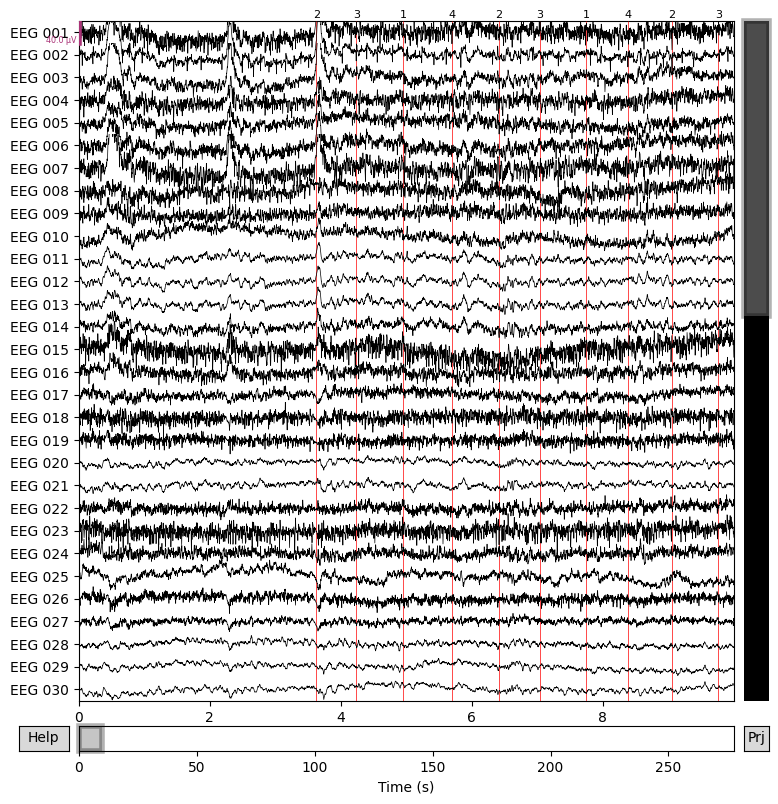

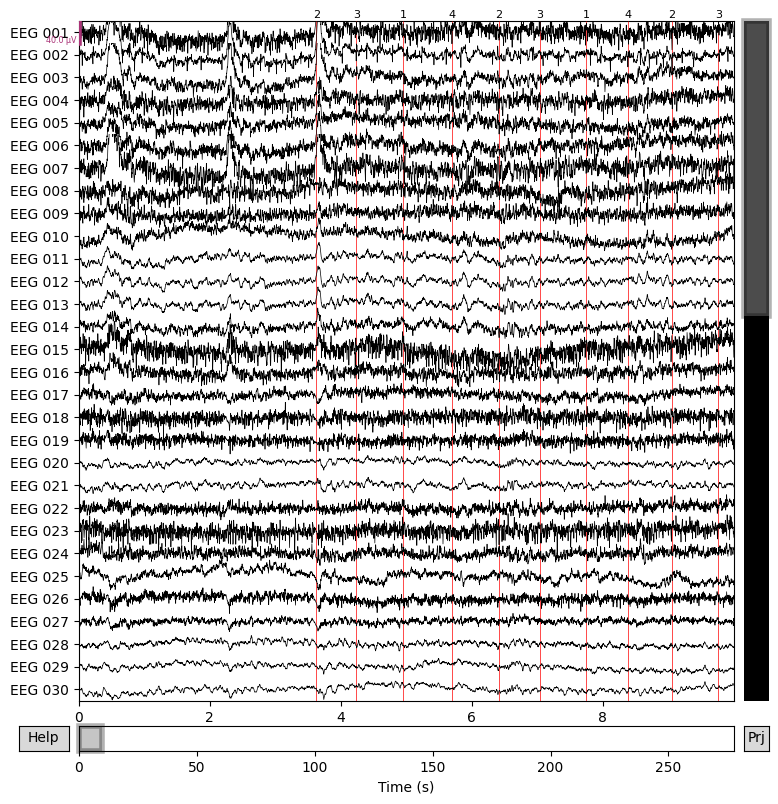

In [7]:

# Step 2: Plot raw EEG data with events
events = mne.find_events(raw, stim_channel='STI 014')
print(events)
event_id = dict(auditory_left=1, auditory_right=2, visual_left=3, visual_right=4)

raw.plot(events=events, duration=10.0, n_channels=30, start=0, event_color='red')


In [8]:

# Step 3: Filter data (band-pass 1-40 Hz)
raw.filter(1., 40., fir_design='firwin')

# # Remove eye-blink artifacts using ICA
# ica = mne.preprocessing.ICA(n_components=15, random_state=97)
# ica.fit(raw)
# ica.plot_components()
# ica.exclude = [0]  # You may manually check plots and update this list
# ica.apply(raw)


Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1983 samples (3.302 s)



<Raw | sample_audvis_raw.fif, 69 x 166800 (277.7 s), ~90.8 MiB, data loaded>

In [19]:

# Step 4: Create epochs around each event
tmin, tmax = -0.2, 0.9  # Epoch time window
epochs = mne.Epochs(raw, events, event_id, tmin, tmax, proj=True,
                    baseline=(None, 0), preload=True, detrend=1)


Not setting metadata
289 matching events found
Setting baseline interval to [-0.19979521315838786, 0.0] s
Applying baseline correction (mode: mean)
Created an SSP operator (subspace dimension = 1)
1 projection items activated
Using data from preloaded Raw for 289 events and 662 original time points ...
0 bad epochs dropped


In [20]:

# Step 5: Extract ERPs (evoked responses)
print("Number of auditory_left epochs:", len(epochs['auditory_left']))
print("Number of auditory_right epochs:", len(epochs['auditory_right']))


evoked_auditory_left = epochs['auditory_left'].average()
evoked_auditory_right = epochs['auditory_right'].average()


Number of auditory_left epochs: 72
Number of auditory_right epochs: 73


Need more than one channel to make topography for eeg. Disabling interactivity.


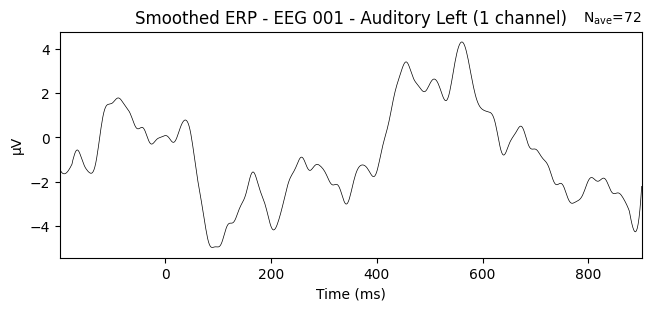

Need more than one channel to make topography for eeg. Disabling interactivity.


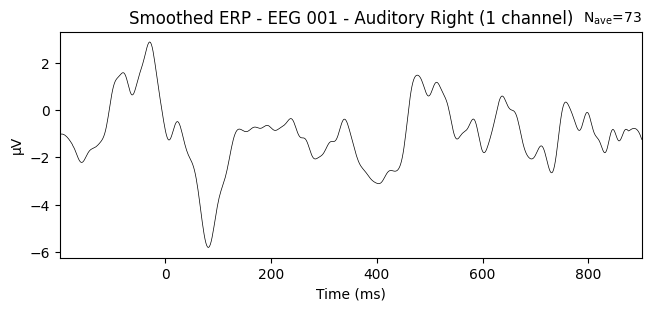

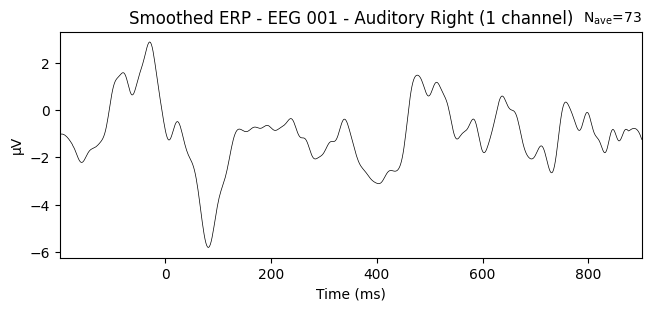

In [21]:

# Step 6: Plot ERP of a single channel (e.g., 'EEG 001')
from scipy.signal import savgol_filter

# Optional: Additional smoothing using Savitzky-Golay filter
evoked_left_smooth = evoked_auditory_left.copy()
evoked_right_smooth = evoked_auditory_right.copy()

for evoked in [evoked_left_smooth, evoked_right_smooth]:
    for i in range(evoked.data.shape[0]):
        evoked.data[i] = savgol_filter(evoked.data[i], window_length=30, polyorder=3)

# Plot for a single channel in milliseconds
channel = 'EEG 001'

evoked_left_smooth.plot(picks=[channel], time_unit='ms',
                        titles=f'Smoothed ERP - {channel} - Auditory Left')

evoked_right_smooth.plot(picks=[channel], time_unit='ms',
                         titles=f'Smoothed ERP - {channel} - Auditory Right')


NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...
NOTE: tfr_multitaper() is a legacy function. New code should use .compute_tfr(method="multitaper").
Applying baseline correction (mode: logratio)


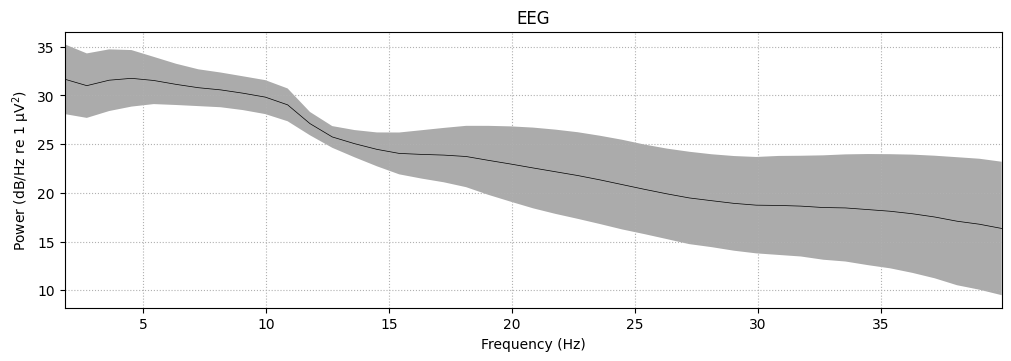

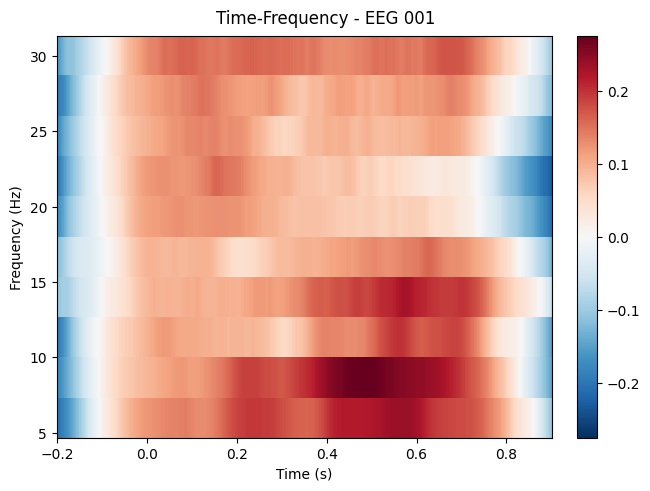

[<Figure size 640x480 with 2 Axes>]

In [22]:

# Step 7: Frequency analysis (FFT or PSD of epochs)
# Calculate power spectral density for one condition
epochs['auditory_left'].plot_psd(fmin=1, fmax=40, average=True)

# Or do frequency decomposition using multitaper
freqs = np.linspace(6, 30, 10)  # 6 to 30 Hz
n_cycles = freqs / 2.  # adaptive cycles
power = mne.time_frequency.tfr_multitaper(epochs['auditory_left'], freqs=freqs,
                                          n_cycles=n_cycles, return_itc=False)

# Plot TFR for the selected channel
power.plot([epochs.ch_names.index(channel)], baseline=(None, 0), mode='logratio',
           title=f'Time-Frequency - {channel}')
